# Clasificación de `ObjetosInteractuadosCorrectamente` en tres clases

Este notebook predice `ObjetosInteractuadosCorrectamente`, agrupado en **bajo**, **medio** y **alto**. Los límites se calculan como terciles usando únicamente los grupos de origen del conjunto de entrenamiento; así las clases parten con una distribución más equilibrada y no se usan etiquetas de validación o test para fijar los cortes.

La separación se realiza por `source_session_id` para mantener juntas las filas derivadas de una misma sesión. Se usan terciles provisionales solo para equilibrar la separación de grupos; los cortes finales de las clases se vuelven a calcular exclusivamente con train. Se excluyen `CantAciertasTotales` y `Precision`, ya que son medidas de resultado estrechamente relacionadas con los objetos acertados. Las métricas son exploratorias y no representan validación clínica.

In [25]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, classification_report, confusion_matrix, f1_score, precision_score, recall_score)
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC

warnings.filterwarnings('ignore')
SEED = 42
TARGET = 'ObjetosInteractuadosCorrectamente'
GROUP = 'source_session_id'
DATA_FILENAME = 'neuroflex_dataset_augmented.csv'
DATA_PATH_CANDIDATES = [Path.cwd() / DATA_FILENAME, Path.cwd() / 'archivos_neuroflex' / DATA_FILENAME, Path.cwd().parent / 'archivos_neuroflex' / DATA_FILENAME]
DATA_PATH = next((p for p in DATA_PATH_CANDIDATES if p.is_file()), DATA_PATH_CANDIDATES[1])
print('Archivo esperado:', DATA_PATH.resolve())

Archivo esperado: C:\Users\cristobal\Downloads\NeuroflexW-main\archivos_neuroflex\neuroflex_dataset_augmented.csv


In [26]:
if not DATA_PATH.is_file():
    searched = '\n'.join(str(p.resolve()) for p in DATA_PATH_CANDIDATES)
    raise FileNotFoundError(f'No se encontró {DATA_FILENAME}. Directorio actual: {Path.cwd()}\nRutas revisadas:\n{searched}')
DATA_PATH = DATA_PATH.resolve()
df = pd.read_csv(DATA_PATH)
required = {TARGET, GROUP}
missing = required.difference(df.columns)
if missing:
    raise KeyError(f'Faltan columnas necesarias: {sorted(missing)}')
df[TARGET] = pd.to_numeric(df[TARGET], errors='coerce')
df = df.dropna(subset=[TARGET, GROUP]).copy()
if df[GROUP].nunique() < 5:
    raise ValueError('Se necesitan al menos cinco grupos de origen')
print(f'Dataset: {DATA_PATH}')
print(f'Filas: {len(df):,} | grupos de origen: {df[GROUP].nunique()}')
display(df[TARGET].describe().to_frame().round(2))

Dataset: C:\Users\cristobal\Downloads\NeuroflexW-main\archivos_neuroflex\neuroflex_dataset_augmented.csv
Filas: 6,000 | grupos de origen: 117


,ObjetosInteractuadosCorrectamente
count,6000.00
mean,4.51
std,3.07
min,0.00
25%,2.00
50%,4.00
75%,7.00
max,9.00


In [27]:
# Crear terciles provisionales solo para equilibrar los folds, sin compartir grupos.
# Los cortes definitivos se vuelven a calcular más abajo usando solo grupos de train.
groups = df[GROUP].astype('string')
all_group_target = df.groupby(GROUP)[TARGET].first()
split_q1, split_q2 = all_group_target.quantile([1/3, 2/3]).tolist()
split_strata = pd.cut(df[TARGET], bins=[-np.inf, split_q1, split_q2, np.inf], labels=[0, 1, 2]).astype(int)
outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
train_val_idx, test_idx = next(outer.split(df, split_strata, groups))
inner = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED + 1)
train_rel, val_rel = next(inner.split(df.iloc[train_val_idx], split_strata.iloc[train_val_idx], groups.iloc[train_val_idx]))
train_idx = train_val_idx[train_rel]
val_idx = train_val_idx[val_rel]
train_df, val_df, test_df = df.iloc[train_idx].copy(), df.iloc[val_idx].copy(), df.iloc[test_idx].copy()

g_train, g_val, g_test = (set(part[GROUP].astype(str)) for part in (train_df, val_df, test_df))
assert g_train.isdisjoint(g_val) and g_train.isdisjoint(g_test) and g_val.isdisjoint(g_test)

# Una observación por grupo evita que los grupos más aumentados pesen más al fijar los cortes.
train_group_target = train_df.groupby(GROUP)[TARGET].first()
q1, q2 = train_group_target.quantile([1/3, 2/3]).tolist()
if not q1 < q2:
    raise ValueError(f'{TARGET} no tiene suficientes valores distintos en train para formar tres clases')
class_names = ['Baja', 'Media', 'Alta']
class_to_id = {name: idx for idx, name in enumerate(class_names)}
def encode_target(values):
    bins = pd.cut(values, bins=[-np.inf, q1, q2, np.inf], labels=class_names, include_lowest=True)
    return bins.map(class_to_id).astype(int)

y_train, y_val, y_test = (encode_target(part[TARGET]) for part in (train_df, val_df, test_df))
print(f'Cortes de {TARGET}, calculados solo con train: Baja <= {q1:.2f} | Media <= {q2:.2f} | Alta > {q2:.2f}')
print(f'Train: {len(train_df):,} filas / {len(g_train)} grupos; validación: {len(val_df):,} / {len(g_val)}; test: {len(test_df):,} / {len(g_test)}')
display(pd.DataFrame({'train': y_train.value_counts(normalize=True), 'validación': y_val.value_counts(normalize=True), 'test': y_test.value_counts(normalize=True)}).rename(index=dict(enumerate(class_names))).fillna(0).round(3))
for name, labels in [('train', y_train), ('validación', y_val), ('test', y_test)]:
    if set(labels.unique()) != {0, 1, 2}:
        raise ValueError(f'La partición {name} no contiene las tres clases; cambia SEED o revisa grupos')

Cortes de ObjetosInteractuadosCorrectamente, calculados solo con train: Baja <= 3.00 | Media <= 6.00 | Alta > 6.00
Train: 3,811 filas / 74 grupos; validación: 973 / 19; test: 1,216 / 24


,train,validación,test
ObjetosInteractuadosCorrectamente,,,
Baja,0.381,0.377,0.381
Media,0.313,0.313,0.299
Alta,0.306,0.309,0.320


In [28]:
# Quitar objetivo, identificadores y métricas de resultado relacionadas
excluded = {TARGET, GROUP, 'session_id', 'timestamp', 'date', 'name', 'rut', 'patient_updated_at', 'CantAciertasTotales', 'Precision'}
feature_cols = [c for c in df.columns if c not in excluded]
if not feature_cols:
    raise ValueError('No quedaron predictores disponibles')
categorical_cols = [c for c in ['dominant_hand', 'TipoEscena'] if c in feature_cols]
numeric_cols = [c for c in feature_cols if c not in categorical_cols]
def make_X(part):
    X = part[feature_cols].copy()
    for col in numeric_cols:
        X[col] = pd.to_numeric(X[col], errors='coerce')
    return X
X_train, X_val, X_test = (make_X(part) for part in (train_df, val_df, test_df))
print('Predictores:', feature_cols)
print('Variables categóricas:', categorical_cols)

Predictores: ['dominant_hand', 'TiempoRespuestaPararse', 'TiempoActivoTarea', 'TiempoRespuestaPregunta1', 'TiempoRespuestaPregunta2', 'TiempoRespuestaPregunta3', 'TiempoCapturarNumero', 'TiempoTutorial', 'TipoEscena']
Variables categóricas: ['dominant_hand', 'TipoEscena']


In [29]:
transformers = []
if numeric_cols:
    transformers.append(('num', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), numeric_cols))
if categorical_cols:
    transformers.append(('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('onehot', OneHotEncoder(handle_unknown='ignore'))]), categorical_cols))
preprocessor = ColumnTransformer(transformers=transformers, remainder='drop')
class DropoutMLPClassifier(ClassifierMixin, BaseEstimator):
    """Compact NumPy MLP with inverted dropout and class-weighted Adam."""
    def __init__(self, hidden_layers=(64, 32), dropout_rate=0.25, learning_rate=0.001, epochs=70, batch_size=128, l2=1e-4, random_state=42):
        self.hidden_layers = hidden_layers
        self.dropout_rate = dropout_rate
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.batch_size = batch_size
        self.l2 = l2
        self.random_state = random_state

    @staticmethod
    def _softmax(logits):
        shifted = logits - logits.max(axis=1, keepdims=True)
        exp_values = np.exp(shifted)
        return exp_values / exp_values.sum(axis=1, keepdims=True)

    def _forward(self, X, training=False):
        z1 = X @ self.W1 + self.b1
        a1 = np.maximum(z1, 0)
        if training:
            self.mask1 = (self.rng.random(a1.shape) >= self.dropout_rate) / (1 - self.dropout_rate)
            a1 = a1 * self.mask1
        z2 = a1 @ self.W2 + self.b2
        a2 = np.maximum(z2, 0)
        if training:
            self.mask2 = (self.rng.random(a2.shape) >= self.dropout_rate) / (1 - self.dropout_rate)
            a2 = a2 * self.mask2
        return a2 @ self.W3 + self.b3, a1, a2, z1, z2

    def fit(self, X, y):
        if not 0 <= self.dropout_rate < 1:
            raise ValueError('dropout_rate debe estar entre 0 y 1')
        if hasattr(X, 'toarray'):
            X = X.toarray()
        X = np.asarray(X, dtype=np.float64)
        y = np.asarray(y)
        self.classes_, encoded = np.unique(y, return_inverse=True)
        n_samples, n_features = X.shape
        self.n_features_in_ = n_features
        n_classes = len(self.classes_)
        if n_classes < 2:
            raise ValueError('Se necesitan al menos dos clases')
        self.rng = np.random.default_rng(self.random_state)
        h1, h2 = self.hidden_layers
        self.W1 = self.rng.normal(0, np.sqrt(2 / max(n_features, 1)), (n_features, h1))
        self.b1 = np.zeros(h1)
        self.W2 = self.rng.normal(0, np.sqrt(2 / h1), (h1, h2))
        self.b2 = np.zeros(h2)
        self.W3 = self.rng.normal(0, np.sqrt(2 / h2), (h2, n_classes))
        self.b3 = np.zeros(n_classes)
        params = [self.W1, self.b1, self.W2, self.b2, self.W3, self.b3]
        m = [np.zeros_like(p) for p in params]
        v = [np.zeros_like(p) for p in params]
        counts = np.bincount(encoded, minlength=n_classes)
        class_weights = n_samples / (n_classes * counts)
        onehot = np.eye(n_classes)[encoded]
        step = 0
        for _ in range(self.epochs):
            order = self.rng.permutation(n_samples)
            for start in range(0, n_samples, self.batch_size):
                ids = order[start:start + self.batch_size]
                xb, yb = X[ids], onehot[ids]
                weights = class_weights[encoded[ids]]
                logits, a1, a2, z1, z2 = self._forward(xb, training=True)
                delta3 = (self._softmax(logits) - yb) * weights[:, None] / weights.sum()
                gW3 = a2.T @ delta3 + self.l2 * self.W3
                gb3 = delta3.sum(axis=0)
                dz2 = ((delta3 @ self.W3.T) * self.mask2) * (z2 > 0)
                gW2 = a1.T @ dz2 + self.l2 * self.W2
                gb2 = dz2.sum(axis=0)
                dz1 = ((dz2 @ self.W2.T) * self.mask1) * (z1 > 0)
                gW1 = xb.T @ dz1 + self.l2 * self.W1
                gb1 = dz1.sum(axis=0)
                step += 1
                for j, (param, grad) in enumerate(zip(params, [gW1, gb1, gW2, gb2, gW3, gb3])):
                    m[j] = 0.9 * m[j] + 0.1 * grad
                    v[j] = 0.999 * v[j] + 0.001 * (grad * grad)
                    mhat = m[j] / (1 - 0.9 ** step)
                    vhat = v[j] / (1 - 0.999 ** step)
                    param -= self.learning_rate * mhat / (np.sqrt(vhat) + 1e-8)
        return self

    def predict_proba(self, X):
        if hasattr(X, 'toarray'):
            X = X.toarray()
        X = np.asarray(X, dtype=np.float64)
        logits, _, _, _, _ = self._forward(X, training=False)
        return self._softmax(logits)

    def predict(self, X):
        return self.classes_[np.argmax(self.predict_proba(X), axis=1)]

models = {
    'Baseline mayoritario': DummyClassifier(strategy='most_frequent'),
    'Regresión logística': LogisticRegression(max_iter=3000, class_weight='balanced', random_state=SEED),
    'Random Forest': RandomForestClassifier(n_estimators=250, min_samples_leaf=2, class_weight='balanced_subsample', n_jobs=-1, random_state=SEED),
    'Extra Trees': ExtraTreesClassifier(n_estimators=250, min_samples_leaf=2, class_weight='balanced', n_jobs=-1, random_state=SEED),
    'SVM RBF': SVC(C=1.0, kernel='rbf', class_weight='balanced'),
    'MLP con Dropout': DropoutMLPClassifier(dropout_rate=0.25, epochs=70, batch_size=128, random_state=SEED),
}
print('Modelos:', list(models))

Modelos: ['Baseline mayoritario', 'Regresión logística', 'Random Forest', 'Extra Trees', 'SVM RBF', 'MLP con Dropout']


In [30]:
results = []
pipelines = {}
for name, estimator in models.items():
    pipe = Pipeline([('preprocessor', clone(preprocessor)), ('model', clone(estimator))])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_val)
    results.append({'modelo': name, 'accuracy': accuracy_score(y_val, pred), 'balanced_accuracy': balanced_accuracy_score(y_val, pred), 'precision_macro': precision_score(y_val, pred, average='macro', zero_division=0), 'recall_macro': recall_score(y_val, pred, average='macro', zero_division=0), 'f1_macro': f1_score(y_val, pred, average='macro', zero_division=0), 'f1_weighted': f1_score(y_val, pred, average='weighted', zero_division=0)})
    pipelines[name] = pipe
results_df = pd.DataFrame(results).sort_values('f1_macro', ascending=False).reset_index(drop=True)
display(results_df.round(3))
best_name = results_df.loc[0, 'modelo']
print('Mejor modelo en validación:', best_name)

,modelo,accuracy,balanced_accuracy,precision_macro,recall_macro,f1_macro,f1_weighted
0,Extra Trees,0.848,0.837,0.863,0.837,0.839,0.845
1,Random Forest,0.838,0.826,0.859,0.826,0.828,0.834
2,SVM RBF,0.734,0.725,0.725,0.725,0.725,0.733
3,MLP con Dropout,0.705,0.694,0.718,0.694,0.692,0.700
4,Regresión logística,0.624,0.608,0.592,0.608,0.596,0.612
5,Baseline mayoritario,0.377,0.333,0.126,0.333,0.183,0.207


Mejor modelo en validación: Extra Trees


In [31]:
X_train_final = pd.concat([X_train, X_val])
y_train_final = pd.concat([y_train, y_val])
final_model = clone(pipelines[best_name])
final_model.fit(X_train_final, y_train_final)
test_pred = final_model.predict(X_test)
labels = [0, 1, 2]
print('Modelo:', best_name)
print(f'Accuracy: {accuracy_score(y_test, test_pred):.3f}')
print(f'Balanced accuracy: {balanced_accuracy_score(y_test, test_pred):.3f}')
print(f'F1 macro: {f1_score(y_test, test_pred, labels=labels, average="macro", zero_division=0):.3f}')
print(f'F1 ponderado: {f1_score(y_test, test_pred, average="weighted", zero_division=0):.3f}')
print('\nReporte por clase:')
print(classification_report(y_test, test_pred, labels=labels, target_names=class_names, zero_division=0, digits=3))

Modelo: Extra Trees
Accuracy: 0.512
Balanced accuracy: 0.495
F1 macro: 0.490
F1 ponderado: 0.500

Reporte por clase:
              precision    recall  f1-score   support

        Baja      0.549     0.711     0.620       463
       Media      0.470     0.346     0.399       364
        Alta      0.479     0.429     0.453       389

    accuracy                          0.512      1216
   macro avg      0.499     0.495     0.490      1216
weighted avg      0.503     0.512     0.500      1216



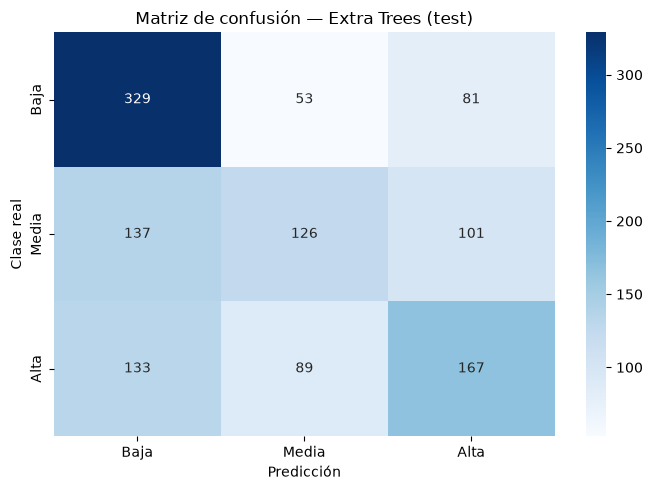

In [32]:
cm = confusion_matrix(y_test, test_pred, labels=[0, 1, 2])
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title(f'Matriz de confusión — {best_name} (test)')
plt.xlabel('Predicción'); plt.ylabel('Clase real'); plt.tight_layout(); plt.show()

## Cómo interpretar el resultado

Los cortes de Baja/Media/Alta son terciles aprendidos de grupos de entrenamiento, no umbrales clínicos. Esto suele equilibrar el número de ejemplos de cada clase y puede mejorar F1 macro frente a clases desbalanceadas, pero no garantiza mejores métricas predictivas. Compara el resultado con el baseline y evalúa el conjunto de test una sola vez. La evaluación sigue dependiendo del dataset aumentado; no es validación clínica.